# Milestone 2 fix

In [3]:
%pip install kaleido==1.5.0 pandas==2.2.3 numpy==2.1.3 plotly==6.1.1 scikit-learn==1.6.1 -q

In [4]:
TRAIN_PATH = "https://raw.githubusercontent.com/lego111Aron/shelter-animal-outcome-prediction/refs/heads/main/Data/Original/train.csv"
TEST_PATH = "https://raw.githubusercontent.com/lego111Aron/shelter-animal-outcome-prediction/refs/heads/main/Data/Original/test.csv"

TARGET = "OutcomeType"
LEAKAGE_COLS = ['OutcomeSubtype']
ID_COLS = ['AnimalID']
DROP_FEATURES = LEAKAGE_COLS + ID_COLS
RANDOM_STATE = 42

PLOTLY_TEMPLATE = "plotly_white"
PLOTLY_CONFIG = {"displaylogo": False, "responsive": True}
PLOTLY_WIDTH = 950
PLOTLY_HEIGHT = 520

## Data Splitting

In [5]:
import pandas as pd
import numpy as np

"""Load data"""
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")

Train shape: (26729, 10)
Test shape: (11456, 8)


In [6]:
"""
Define the target variable (y) and input features (X).
Drop the columns that will not be used during model training
(the target itself, the target subtype, and the unique identifier).
"""
y = train_df[TARGET]

drop_cols = DROP_FEATURES + [TARGET]
X = train_df.drop(columns=[col for col in drop_cols if col in train_df.columns])

print("Selected features:", list(X.columns))

Selected features: ['Name', 'DateTime', 'AnimalType', 'SexuponOutcome', 'AgeuponOutcome', 'Breed', 'Color']


## Proper train/dev/test split


In [7]:
from sklearn.model_selection import train_test_split

# First: separate the final test set (20%)
X_train_dev, X_test, y_train_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Then: split the remaining data into train and dev
# 25% of the remaining 80% = 20% of the original dataset
X_train, X_dev, y_train, y_dev = train_test_split(
    X_train_dev,
    y_train_dev,
    test_size=0.25,
    stratify=y_train_dev,
    random_state=RANDOM_STATE
)

print(f"Train shape: {X_train.shape}")
print(f"Dev shape:   {X_dev.shape}")
print(f"Test shape:  {X_test.shape}")

Train shape: (16037, 7)
Dev shape:   (5346, 7)
Test shape:  (5346, 7)


## Distribution check (revised version after milestone 2 results)

In [8]:
"""
Check the distribution of the target variable across the
train, development, and test sets.

Stratification should preserve approximately the same class
proportions in each split.
"""

total_dist = y.value_counts(normalize=True) * 100
train_dist = y_train.value_counts(normalize=True) * 100
dev_dist = y_dev.value_counts(normalize=True) * 100
test_dist = y_test.value_counts(normalize=True) * 100

check_df = pd.DataFrame({
    'Total %': total_dist,
    'Train %': train_dist,
    'Dev %': dev_dist,
    'Test %': test_dist
})

print(check_df)

                   Total %    Train %      Dev %     Test %
OutcomeType                                                
Adoption         40.289573  40.288084  40.291807  40.291807
Transfer         35.250103  35.249735  35.241302  35.260007
Return_to_owner  17.905646  17.908586  17.901235  17.901235
Euthanasia        5.817651   5.817796   5.817434   5.817434
Died              0.737027   0.735798   0.748223   0.729517


## Data cleaning (revised after milestone 2 results)

In [9]:
splits = {
    "Train": X_train,
    "Dev": X_dev,
    "Test": X_test
}

columns_to_check = [
    'Name',
    'SexuponOutcome',
    'AgeuponOutcome',
    'Breed',
    'Color'
]

for split_name, df in splits.items():
    print(f"\nMissing values in {split_name}:")
    print(df[columns_to_check].isnull().sum())


Missing values in Train:
Name              4658
SexuponOutcome       1
AgeuponOutcome      13
Breed                0
Color                0
dtype: int64

Missing values in Dev:
Name              1526
SexuponOutcome       0
AgeuponOutcome       2
Breed                0
Color                0
dtype: int64

Missing values in Test:
Name              1507
SexuponOutcome       0
AgeuponOutcome       3
Breed                0
Color                0
dtype: int64


In [10]:
MONTH_CONVERSION = {
    'year': 12.0,
    'month': 1.0,
    'week': 7 / 30.4375,
    'day': 1 / 30.4375
}

def parse_age_in_months(age_str):
    if pd.isna(age_str):
        return np.nan

    parts = str(age_str).split()

    if len(parts) < 2:
        return np.nan

    number = float(parts[0])
    unit = parts[1].lower().rstrip('s')

    return number * MONTH_CONVERSION.get(unit, np.nan)

In [11]:
for df in [X_train, X_dev, X_test]:
    df['AgeInMonths'] = df['AgeuponOutcome'].apply(
        parse_age_in_months
    )

In [12]:
for df in [X_train, X_dev, X_test]:
    df['Name'] = df['Name'].fillna('No Name')
    df['SexuponOutcome'] = df['SexuponOutcome'].fillna('Unknown')

In [13]:
"""Calculate the median in the training dataset and impute the
missing values in the dev and test splits based on the data learned
from the training data"""

age_medians_by_type = (
    X_train.groupby('AnimalType')['AgeInMonths']
    .median()
)
# fallback global median
global_age_median = X_train['AgeInMonths'].median()

for df in [X_train, X_dev, X_test]:
    df['AgeInMonths'] = df['AgeInMonths'].fillna(
        df['AnimalType'].map(age_medians_by_type)
    )
    # fallback in case some values are still missing
    df['AgeInMonths'] = df['AgeInMonths'].fillna(
        global_age_median
    )


In [14]:
"""
Verify that no missing values remain in the specified columns
"""
columns_to_verify = [
    'Name',
    'SexuponOutcome',
    'AgeInMonths'
]

for split_name, df in splits.items():
    print(f"\nRemaining missing values in {split_name}:")
    print(df[columns_to_verify].isnull().sum())


Remaining missing values in Train:
Name              0
SexuponOutcome    0
AgeInMonths       0
dtype: int64

Remaining missing values in Dev:
Name              0
SexuponOutcome    0
AgeInMonths       0
dtype: int64

Remaining missing values in Test:
Name              0
SexuponOutcome    0
AgeInMonths       0
dtype: int64


## Data transformation (revised)

In [15]:

# ============================================================
# DATA TRANSFORMATION
# ============================================================

from sklearn.preprocessing import StandardScaler, OneHotEncoder

# ------------------------------------------------------------
# 1. Numerical transformations
# ------------------------------------------------------------

# Apply deterministic log transformation
for df in [X_train, X_dev, X_test]:
    df['AgeInMonths_log'] = np.log1p(df['AgeInMonths'])

# Fit scaler exclusively on training data
scaler = StandardScaler()

X_train['AgeInMonths_scaled'] = scaler.fit_transform(
    X_train[['AgeInMonths_log']]
)

# Apply fitted scaler to dev and test
X_dev['AgeInMonths_scaled'] = scaler.transform(
    X_dev[['AgeInMonths_log']]
)

X_test['AgeInMonths_scaled'] = scaler.transform(
    X_test[['AgeInMonths_log']]
)


# ------------------------------------------------------------
# 2. DateTime conversion
# ------------------------------------------------------------

for df in [X_train, X_dev, X_test]:
    df['DateTime'] = pd.to_datetime(df['DateTime'])


# ------------------------------------------------------------
# 3. Frequency Encoding
# ------------------------------------------------------------

for col in ['Breed', 'Color']:

    # Learn frequency mapping from training data only
    freq_map = X_train[col].value_counts(normalize=True).to_dict()

    # Apply the same mapping to every split
    for df in [X_train, X_dev, X_test]:
        df[f'{col}_freq'] = df[col].map(freq_map).fillna(0)


# ------------------------------------------------------------
# 4. One-Hot Encoding
# ------------------------------------------------------------

categorical_cols = ['AnimalType', 'SexuponOutcome']

encoder = OneHotEncoder(
    drop='first',
    handle_unknown='ignore',
    sparse_output=False
)

# Fit and transform training data
train_encoded = encoder.fit_transform(
    X_train[categorical_cols]
)

# Transform dev and test using the fitted encoder
dev_encoded = encoder.transform(
    X_dev[categorical_cols]
)

test_encoded = encoder.transform(
    X_test[categorical_cols]
)

# Obtain consistent feature names
encoded_feature_names = encoder.get_feature_names_out(
    categorical_cols
)

# Convert encoded arrays into DataFrames
train_encoded_df = pd.DataFrame(
    train_encoded,
    columns=encoded_feature_names,
    index=X_train.index
)

dev_encoded_df = pd.DataFrame(
    dev_encoded,
    columns=encoded_feature_names,
    index=X_dev.index
)

test_encoded_df = pd.DataFrame(
    test_encoded,
    columns=encoded_feature_names,
    index=X_test.index
)

# Replace original categorical columns with encoded features
X_train = pd.concat(
    [X_train.drop(columns=categorical_cols), train_encoded_df],
    axis=1
)

X_dev = pd.concat(
    [X_dev.drop(columns=categorical_cols), dev_encoded_df],
    axis=1
)

X_test = pd.concat(
    [X_test.drop(columns=categorical_cols), test_encoded_df],
    axis=1
)


# ------------------------------------------------------------
# 5. Name availability feature
# ------------------------------------------------------------

for df in [X_train, X_dev, X_test]:
    df['has_name'] = (df['Name'] != 'No Name').astype(int)


# ------------------------------------------------------------
# 6. Verify consistent feature spaces
# ------------------------------------------------------------

print("Train shape:", X_train.shape)
print("Dev shape:", X_dev.shape)
print("Test shape:", X_test.shape)

print("\nDo all splits have identical feature columns?")

print("Train vs Dev:", X_train.columns.equals(X_dev.columns))
print("Train vs Test:", X_train.columns.equals(X_test.columns))


Train shape: (16037, 16)
Dev shape: (5346, 16)
Test shape: (5346, 16)

Do all splits have identical feature columns?
Train vs Dev: True
Train vs Test: True


## Feature Engineering (revised)

In [16]:
def create_features(df):
    df = df.copy()

    # --- Temporal features ---
    month = df['DateTime'].dt.month
    weekday = df['DateTime'].dt.dayofweek
    hour = df['DateTime'].dt.hour

    df['month_sin'] = np.sin(2 * np.pi * month / 12)
    df['month_cos'] = np.cos(2 * np.pi * month / 12)

    df['weekday_sin'] = np.sin(2 * np.pi * weekday / 7)
    df['weekday_cos'] = np.cos(2 * np.pi * weekday / 7)

    df['hour_sin'] = np.sin(2 * np.pi * hour / 24)
    df['hour_cos'] = np.cos(2 * np.pi * hour / 24)

    # --- Breed features ---
    df['is_mixed_breed'] = (
        df['Breed']
        .str.contains(r'\bMix\b|/', case=False, na=False)
        .astype(int)
    )

    return df


X_train = create_features(X_train)
X_dev = create_features(X_dev)
X_test = create_features(X_test)

## Final feature preparation

In [17]:
# Raw columns replaced by engineered or encoded features
RAW_COLUMNS_TO_DROP = [
    'Name',
    'DateTime',
    'AgeuponOutcome',
    'AgeInMonths',
    'AgeInMonths_log',
    'Breed',
    'Color',
]

# Identifiers and columns that must never be model features
NON_FEATURE_COLUMNS = [
    'AnimalID',
    'ID',
]

def finalize_features(df):
    df = df.copy()

    cols_to_drop = RAW_COLUMNS_TO_DROP + NON_FEATURE_COLUMNS

    df = df.drop(
        columns=[col for col in cols_to_drop if col in df.columns]
    )

    return df

X_train_final = finalize_features(X_train)
X_dev_final = finalize_features(X_dev)
X_test_final = finalize_features(X_test)

# Ensure no target or leakage columns remain in the features
for name, df in [
    ('Train', X_train_final),
    ('Dev', X_dev_final),
    ('Test', X_test_final),
]:
    forbidden = {'OutcomeType', 'OutcomeSubtype', 'fold'}
    remaining = forbidden.intersection(df.columns)

    assert not remaining, f"{name} contains forbidden columns: {remaining}"

# Ensure all splits have identical features in identical order
assert X_train_final.columns.equals(X_dev_final.columns)
assert X_train_final.columns.equals(X_test_final.columns)

print(f"Train features: {X_train_final.shape}")
print(f"Dev features:   {X_dev_final.shape}")
print(f"Test features:  {X_test_final.shape}")

Train features: (16037, 16)
Dev features:   (5346, 16)
Test features:  (5346, 16)



## Feature analysis

### Age outcome distribution

In [18]:
import plotly.express as px

age_data = pd.DataFrame({
    'AgeInMonths': X_train['AgeInMonths'],
    'OutcomeType': y_train
})

fig_age = px.box(
    age_data,
    x='OutcomeType',
    y='AgeInMonths',
    color='OutcomeType',
    title='Age Distribution Across Outcome Categories',
    labels={
        'OutcomeType': 'Outcome Type',
        'AgeInMonths': 'Age (Months)'
    }
)
fig_age.update_yaxes(type='log')
fig_age.update_layout(showlegend=False)
fig_age.show()

### Mixed-breed outcome distribution

In [19]:

mix_outcome = pd.crosstab(
    y_train,
    X_train_final['is_mixed_breed'],
    normalize='columns'
) * 100

mix_outcome = mix_outcome.rename_axis('OutcomeType').reset_index()

mix_melted = mix_outcome.melt(
    id_vars='OutcomeType',
    var_name='is_mixed_breed',
    value_name='Percentage'
)

mix_melted['is_mixed_breed'] = mix_melted['is_mixed_breed'].map({
    0: 'Purebred',
    1: 'Mixed breed'
})

fig = px.bar(
    mix_melted,
    x='OutcomeType',
    y='Percentage',
    color='is_mixed_breed',
    barmode='group',
    title='Outcome Distribution Across Purebred and Mixed Animals',
    labels={
        'OutcomeType': 'Outcome Type',
        'Percentage': 'Share Within Group (%)',
        'is_mixed_breed': 'Breed Classification'
    }
)

fig.show()

### Name availability distribution

In [20]:
name_outcome = pd.crosstab(
    y_train,
    X_train_final['has_name'],
    normalize='columns'
) * 100

name_outcome = name_outcome.rename_axis('OutcomeType').reset_index()

name_outcome.columns = ['OutcomeType', 'No Name (0)', 'Has Name (1)']

name_melted = name_outcome.melt(
    id_vars='OutcomeType',
    var_name='Name Status',
    value_name='Percentage (%)'
)

fig = px.bar(
    name_melted,
    x='OutcomeType',
    y='Percentage (%)',
    color='Name Status',
    barmode='group',
    title='Outcome Distribution by Name Availability',
    labels={
        'OutcomeType': 'Outcome Type',
        'Percentage (%)': 'Share Within Group (%)',
    }
)

fig.update_layout(xaxis_tickangle=-15)
fig.show()

### Temporal outcome distributions

In [21]:
monthly_data = pd.DataFrame({
    'month': X_train['DateTime'].dt.month,
    'OutcomeType': y_train
})

month_outcome = pd.crosstab(
    monthly_data['month'],
    monthly_data['OutcomeType'],
    normalize='index'
) * 100

month_outcome = month_outcome.rename_axis('month').reset_index()

month_outcome_melted = month_outcome.melt(
    id_vars='month',
    var_name='OutcomeType',
    value_name='Percentage'
)

fig = px.line(
    month_outcome_melted,
    x='month',
    y='Percentage',
    color='OutcomeType',
    markers=True,
    title='Percentage Trend of Outcomes Across Months (Seasonality Analysis)',
    labels={
        'month': 'Month',
        'Percentage': 'Share (%)',
        'OutcomeType': 'Outcome Type'
    }
)

fig.update_xaxes(
    tickmode='array',
    tickvals=list(range(1, 13)),
    ticktext=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
              'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

fig.show()

### Mutual information

In [22]:
from sklearn.feature_selection import mutual_info_classif

# Identify binary features, which should be treated as discrete.
discrete_mask = (
    X_train_final.nunique(dropna=False) <= 2
).to_numpy()

# Calculate mutual information using training data only.
mi_scores = mutual_info_classif(
    X_train_final,
    y_train,
    discrete_features=discrete_mask,
    random_state=RANDOM_STATE
)

# Create a ranked feature importance table.
mi_results = pd.DataFrame({
    'Feature': X_train_final.columns,
    'Mutual Information': mi_scores
}).sort_values(
    by='Mutual Information',
    ascending=False
).reset_index(drop=True)

print("=== FEATURE RELEVANCE: MUTUAL INFORMATION ===")
print(mi_results.to_string(index=False))

fig_mi = px.bar(
    mi_results.sort_values(
        by='Mutual Information',
        ascending=True
    ),
    x='Mutual Information',
    y='Feature',
    orientation='h',
    title='Feature Relevance Based on Mutual Information',
    labels={
        'Mutual Information': 'Mutual Information Score',
        'Feature': 'Feature'
    }
)

fig_mi.show()

=== FEATURE RELEVANCE: MUTUAL INFORMATION ===
                     Feature  Mutual Information
          AgeInMonths_scaled            0.190131
                    has_name            0.108282
                  Breed_freq            0.080361
                    hour_sin            0.079447
                    hour_cos            0.074334
  SexuponOutcome_Intact Male            0.065089
              AnimalType_Dog            0.063437
SexuponOutcome_Spayed Female            0.048568
                  Color_freq            0.044509
SexuponOutcome_Neutered Male            0.040497
      SexuponOutcome_Unknown            0.035325
                 weekday_sin            0.012643
                 weekday_cos            0.005568
                   month_sin            0.004593
              is_mixed_breed            0.003180
                   month_cos            0.002666


### Feature correlation matrix

In [23]:
# Correlation analysis between numerical features only.
numeric_features = X_train_final.select_dtypes(
    include=[np.number]
)

print("Numeric features:")
for col in numeric_features.columns: print(col)

corr_matrix = numeric_features.corr(method='pearson')

fig_corr = px.imshow(
    corr_matrix,
    text_auto=".2f",
    aspect="auto",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="Feature-to-Feature Correlation Matrix"
)

fig_corr.show()

threshold = 0.8

upper_tri = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = [
    (row, col, upper_tri.loc[row, col])
    for col in upper_tri.columns
    for row in upper_tri.index
    if abs(upper_tri.loc[row, col]) > threshold
]

print("=== HIGHLY CORRELATED FEATURE PAIRS ===")

if high_corr_pairs:
    for feature_1, feature_2, correlation in high_corr_pairs:
        print(
            f"{feature_1} <-> {feature_2}: "
            f"{correlation:.3f}"
        )
else:
    print("No highly correlated feature pairs found.")

Numeric features:
AgeInMonths_scaled
Breed_freq
Color_freq
AnimalType_Dog
SexuponOutcome_Intact Male
SexuponOutcome_Neutered Male
SexuponOutcome_Spayed Female
SexuponOutcome_Unknown
has_name
month_sin
month_cos
weekday_sin
weekday_cos
hour_sin
hour_cos
is_mixed_breed


=== HIGHLY CORRELATED FEATURE PAIRS ===
Breed_freq <-> AnimalType_Dog: -0.819


### Final class distribution check

In [24]:
class_distribution = y_train.value_counts().to_frame('Count')

class_distribution['Percentage'] = (
    y_train.value_counts(normalize=True) * 100
)

display(class_distribution)

,Count,Percentage
OutcomeType,,
Adoption,6461,40.288084
Transfer,5653,35.249735
Return_to_owner,2872,17.908586
Euthanasia,933,5.817796
Died,118,0.735798


# Milestone 3

## Evaluation metrics


-  **Macro F1:** primary metric. Calculates F1 independently for each class and takes their unweighted average.

- **Balanced accuracy:** average recall across all classes.

- **Accuracy:** overall percentage of correct predictions.

- **Weighted F1:** F1 averaged according to class frequency.

In [25]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

def evaluate_model(y_true, y_pred, model_name):
    print(f"--- {model_name} ---")

    print(f"Accuracy:          {accuracy_score(y_true, y_pred):.4f}")
    print(f"Balanced Accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")
    print(f"Macro F1:          {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
    print(f"Weighted F1:       {f1_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))


## Baseline model

In [26]:
from sklearn.dummy import DummyClassifier

# Initialize baseline model
baseline = DummyClassifier(strategy='most_frequent')

# Train on the training set
baseline.fit(X_train_final, y_train)

# Predict outcomes for the development set
y_dev_pred_baseline = baseline.predict(X_dev_final)

# Evaluate baseline
evaluate_model(y_dev, y_dev_pred_baseline, "Dummy Classifier (Most Frequent)")

--- Dummy Classifier (Most Frequent) ---
Accuracy:          0.4029
Balanced Accuracy: 0.2000
Macro F1:          0.1149
Weighted F1:       0.2314

Classification Report:
                 precision    recall  f1-score   support

       Adoption       0.40      1.00      0.57      2154
           Died       0.00      0.00      0.00        40
     Euthanasia       0.00      0.00      0.00       311
Return_to_owner       0.00      0.00      0.00       957
       Transfer       0.00      0.00      0.00      1884

       accuracy                           0.40      5346
      macro avg       0.08      0.20      0.11      5346
   weighted avg       0.16      0.40      0.23      5346



## The other 2 models

### Decision tree model

In [27]:

from sklearn.tree import DecisionTreeClassifier

# Initialize Decision Tree
decision_tree = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=RANDOM_STATE
)

# Train
decision_tree.fit(X_train_final, y_train)

# Predict on development set
y_dev_pred_tree = decision_tree.predict(X_dev_final)

# Evaluate
evaluate_model(y_dev, y_dev_pred_tree, "Decision Tree")


--- Decision Tree ---
Accuracy:          0.5799
Balanced Accuracy: 0.4114
Macro F1:          0.4124
Weighted F1:       0.5814

Classification Report:
                 precision    recall  f1-score   support

       Adoption       0.67      0.65      0.66      2154
           Died       0.14      0.10      0.12        40
     Euthanasia       0.23      0.25      0.24       311
Return_to_owner       0.38      0.40      0.39       957
       Transfer       0.65      0.65      0.65      1884

       accuracy                           0.58      5346
      macro avg       0.41      0.41      0.41      5346
   weighted avg       0.58      0.58      0.58      5346



### Neural Network (PyTorch MLP)

In [28]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import LabelEncoder

# Reproducibility
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Encode target labels as integers
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_dev_encoded = label_encoder.transform(y_dev)

# Convert features and labels to PyTorch tensors
X_train_tensor = torch.tensor(
    X_train_final.to_numpy(dtype=np.float32),
    dtype=torch.float32
)
y_train_tensor = torch.tensor(y_train_encoded, dtype=torch.long)

X_dev_tensor = torch.tensor(
    X_dev_final.to_numpy(dtype=np.float32),
    dtype=torch.float32
)

# Create training DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

# Define MLP architecture
class MLP(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)


# Initialize model
mlp = MLP(
    input_size=X_train_tensor.shape[1],
    num_classes=len(label_encoder.classes_)
).to(device)

# Calculate class weights to handle class imbalance
class_counts = np.bincount(y_train_encoded)
class_weights = len(y_train_encoded) / (
    len(class_counts) * class_counts
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

# Loss function and optimizer
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.AdamW(mlp.parameters(), lr=0.001)

# Training loop
EPOCHS = 50

mlp.train()

for epoch in range(EPOCHS):
    total_loss = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Forward pass
        outputs = mlp(X_batch)
        loss = criterion(outputs, y_batch)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    if (epoch + 1) % 10 == 0:
        avg_loss = total_loss / len(train_loader)
        print(f"Epoch [{epoch + 1}/{EPOCHS}], Loss: {avg_loss:.4f}")


# Evaluate on development set
mlp.eval()

with torch.no_grad():
    X_dev_tensor = X_dev_tensor.to(device)
    outputs = mlp(X_dev_tensor)
    y_dev_pred_encoded = torch.argmax(outputs, dim=1).cpu().numpy()

# Convert predictions back to original class labels
y_dev_pred_mlp = label_encoder.inverse_transform(y_dev_pred_encoded)

# Evaluate model
evaluate_model(y_dev, y_dev_pred_mlp, "PyTorch MLP")


Using device: cuda
Epoch [10/50], Loss: 1.1417
Epoch [20/50], Loss: 1.1046
Epoch [30/50], Loss: 1.0680
Epoch [40/50], Loss: 1.0456
Epoch [50/50], Loss: 1.0328
--- PyTorch MLP ---
Accuracy:          0.5494
Balanced Accuracy: 0.5254
Macro F1:          0.4262
Weighted F1:       0.5756

Classification Report:
                 precision    recall  f1-score   support

       Adoption       0.75      0.65      0.70      2154
           Died       0.04      0.50      0.08        40
     Euthanasia       0.28      0.39      0.33       311
Return_to_owner       0.39      0.70      0.50       957
       Transfer       0.83      0.39      0.53      1884

       accuracy                           0.55      5346
      macro avg       0.46      0.53      0.43      5346
   weighted avg       0.68      0.55      0.58      5346



## Hyperparamter optimization

### DecisionTree

In [29]:

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint

# Base model
tree = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=RANDOM_STATE
)

# Hyperparameter search space
param_distributions = {
    'max_depth': [None, 5, 10, 15, 20, 30, 40],
    'min_samples_split': randint(2, 30),
    'min_samples_leaf': randint(1, 20),
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_features': [None, 'sqrt', 'log2'],
    'ccp_alpha': [0.0, 0.0001, 0.001, 0.01]
}

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Randomized search
tree_search = RandomizedSearchCV(
    estimator=tree,
    param_distributions=param_distributions,
    n_iter=60,
    scoring='f1_macro',
    cv=cv,
    verbose=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True
)

# Run optimization using training data only
tree_search.fit(X_train_final, y_train)

# Retrieve best model
best_tree = tree_search.best_estimator_

print("Best hyperparameters:")
print(tree_search.best_params_)

print(f"\nBest CV Macro F1: {tree_search.best_score_:.4f}")

# Evaluate optimized model on development set
y_dev_pred_best_tree = best_tree.predict(X_dev_final)

evaluate_model(
    y_dev,
    y_dev_pred_best_tree,
    "Optimized Decision Tree"
)


Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best hyperparameters:
{'ccp_alpha': 0.001, 'criterion': 'entropy', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 2}

Best CV Macro F1: 0.4369
--- Optimized Decision Tree ---
Accuracy:          0.5638
Balanced Accuracy: 0.4934
Macro F1:          0.4320
Weighted F1:       0.5895

Classification Report:
                 precision    recall  f1-score   support

       Adoption       0.73      0.62      0.67      2154
           Died       0.07      0.28      0.11        40
     Euthanasia       0.20      0.45      0.28       311
Return_to_owner       0.40      0.62      0.49       957
       Transfer       0.80      0.50      0.61      1884

       accuracy                           0.56      5346
      macro avg       0.44      0.49      0.43      5346
   weighted avg       0.66      0.56      0.59      5346



### Neural Network

In [30]:
%pip install -q optuna

In [31]:

import copy
import optuna

from sklearn.preprocessing import LabelEncoder

# --------------------------------------------------
# 1. Preparation
# --------------------------------------------------

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Encode target labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)

# Convert features to NumPy arrays
X_train_np = X_train_final.to_numpy(dtype=np.float32)
y_train_np = np.asarray(y_train_encoded)

X_dev_np = X_dev_final.to_numpy(dtype=np.float32)

num_classes = len(label_encoder.classes_)
input_size = X_train_np.shape[1]

# Create an internal validation split.
# X_dev_final remains untouched during optimization.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_np,
    y_train_np,
    test_size=0.15,
    stratify=y_train_np,
    random_state=RANDOM_STATE
)


# --------------------------------------------------
# 2. Configurable MLP architecture
# --------------------------------------------------

class MLP(nn.Module):
    def __init__(self, input_size, num_classes,
                 hidden1, hidden2, dropout):
        super().__init__()

        layers = [
            nn.Linear(input_size, hidden1),
            nn.ReLU(),
            nn.Dropout(dropout)
        ]

        if hidden2 > 0:
            layers.extend([
                nn.Linear(hidden1, hidden2),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            last_size = hidden2
        else:
            last_size = hidden1

        layers.append(nn.Linear(last_size, num_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


# --------------------------------------------------
# 3. Training function with early stopping
# --------------------------------------------------

def train_with_early_stopping(model, X_fit, y_fit,
                              X_val, y_val, params,
                              max_epochs=100, patience=12):

    X_fit_tensor = torch.tensor(X_fit, dtype=torch.float32)
    y_fit_tensor = torch.tensor(y_fit, dtype=torch.long)

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)

    train_dataset = TensorDataset(X_fit_tensor, y_fit_tensor)

    train_loader = DataLoader(
        train_dataset,
        batch_size=params['batch_size'],
        shuffle=True
    )

    # Calculate class weights from fitting data only
    class_counts = np.bincount(y_fit, minlength=num_classes)

    class_weights = len(y_fit) / (
        num_classes * class_counts
    )

    class_weights_tensor = torch.tensor(
        class_weights,
        dtype=torch.float32
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=params['learning_rate'],
        weight_decay=params['weight_decay']
    )

    best_score = -1
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(max_epochs):

        model.train()

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

        # Validate after each epoch
        model.eval()

        with torch.no_grad():
            outputs = model(X_val_tensor)
            predictions = torch.argmax(outputs, dim=1).cpu().numpy()

        val_score = f1_score(
            y_val,
            predictions,
            average='macro',
            zero_division=0
        )

        # Early stopping
        if val_score > best_score:
            best_score = val_score
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_state)

    return best_score, best_epoch


# --------------------------------------------------
# 4. Optuna objective function
# --------------------------------------------------

def objective(trial):

    params = {
        'hidden1': trial.suggest_categorical(
            'hidden1', [32, 64, 128, 256]
        ),
        'hidden2': trial.suggest_categorical(
            'hidden2', [0, 32, 64, 128]
        ),
        'dropout': trial.suggest_float(
            'dropout', 0.1, 0.5
        ),
        'learning_rate': trial.suggest_float(
            'learning_rate', 1e-4, 1e-2, log=True
        ),
        'batch_size': trial.suggest_categorical(
            'batch_size', [64, 128, 256]
        ),
        'weight_decay': trial.suggest_float(
            'weight_decay', 1e-6, 1e-2, log=True
        )
    }

    # Reproducibility for each trial
    torch.manual_seed(RANDOM_STATE + trial.number)
    np.random.seed(RANDOM_STATE + trial.number)

    model = MLP(
        input_size,
        num_classes,
        params['hidden1'],
        params['hidden2'],
        params['dropout']
    ).to(device)

    best_score, best_epoch = train_with_early_stopping(
        model,
        X_fit, y_fit,
        X_val, y_val,
        params
    )

    trial.set_user_attr('best_epoch', best_epoch)

    return best_score


# --------------------------------------------------
# 5. Run optimization
# --------------------------------------------------

study = optuna.create_study(
    direction='maximize',
    study_name='animal_shelter_mlp',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)

study.optimize(objective, n_trials=30)

print("\nBest hyperparameters:")
print(study.best_params)

print(f"\nBest validation Macro F1: {study.best_value:.4f}")
print(
    f"Best epoch: "
    f"{study.best_trial.user_attrs['best_epoch']}"
)


# --------------------------------------------------
# 6. Retrain best model on the full training set
# --------------------------------------------------

best_params = study.best_params
best_epoch = study.best_trial.user_attrs['best_epoch']

torch.manual_seed(RANDOM_STATE)

best_mlp = MLP(
    input_size,
    num_classes,
    best_params['hidden1'],
    best_params['hidden2'],
    best_params['dropout']
).to(device)

X_train_tensor = torch.tensor(
    X_train_np, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_np, dtype=torch.long
)

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=best_params['batch_size'],
    shuffle=True
)

# Recalculate class weights using the full training set
class_counts = np.bincount(
    y_train_np, minlength=num_classes
)

class_weights = len(y_train_np) / (
    num_classes * class_counts
)

class_weights_tensor = torch.tensor(
    class_weights, dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

optimizer = torch.optim.AdamW(
    best_mlp.parameters(),
    lr=best_params['learning_rate'],
    weight_decay=best_params['weight_decay']
)

best_mlp.train()

for epoch in range(best_epoch):
    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = best_mlp(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()


# --------------------------------------------------
# 7. Evaluate on the development set
# --------------------------------------------------

best_mlp.eval()

X_dev_tensor = torch.tensor(
    X_dev_np, dtype=torch.float32
).to(device)

with torch.no_grad():
    outputs = best_mlp(X_dev_tensor)
    y_dev_pred_encoded = torch.argmax(
        outputs, dim=1
    ).cpu().numpy()

y_dev_pred_mlp_optuna = label_encoder.inverse_transform(
    y_dev_pred_encoded
)

evaluate_model(
    y_dev,
    y_dev_pred_mlp_optuna,
    "Optimized PyTorch MLP"
)


[I 2026-11-19 19:42:28,033] A new study created in memory with name: animal_shelter_mlp


Using device: cuda


[I 2026-11-19 19:42:44,017] Trial 0 finished with value: 0.4486002069662547 and parameters: {'hidden1': 64, 'hidden2': 128, 'dropout': 0.34044600469728353, 'learning_rate': 0.0026070247583707684, 'batch_size': 128, 'weight_decay': 7.068974950624607e-06}. Best is trial 0 with value: 0.4486002069662547.
[I 2026-11-19 19:43:06,218] Trial 1 finished with value: 0.4592071129620677 and parameters: {'hidden1': 256, 'hidden2': 64, 'dropout': 0.21685785941408728, 'learning_rate': 0.0005404103854647331, 'batch_size': 128, 'weight_decay': 0.00011400863701127338}. Best is trial 1 with value: 0.4592071129620677.
[I 2026-11-19 19:43:13,341] Trial 2 finished with value: 0.4162671470937861 and parameters: {'hidden1': 128, 'hidden2': 64, 'dropout': 0.2218455076693483, 'learning_rate': 0.0001567993391672301, 'batch_size': 64, 'weight_decay': 9.565499215943819e-05}. Best is trial 1 with value: 0.4592071129620677.
[I 2026-11-19 19:43:24,930] Trial 3 finished with value: 0.43209682043709796 and parameters:


Best hyperparameters:
{'hidden1': 256, 'hidden2': 0, 'dropout': 0.3260828576251979, 'learning_rate': 0.0035385232968796394, 'batch_size': 256, 'weight_decay': 0.0010488781520201834}

Best validation Macro F1: 0.4787
Best epoch: 32
--- Optimized PyTorch MLP ---
Accuracy:          0.5789
Balanced Accuracy: 0.5407
Macro F1:          0.4514
Weighted F1:       0.6069

Classification Report:
                 precision    recall  f1-score   support

       Adoption       0.79      0.62      0.70      2154
           Died       0.06      0.42      0.10        40
     Euthanasia       0.27      0.44      0.34       311
Return_to_owner       0.40      0.74      0.52       957
       Transfer       0.82      0.48      0.61      1884

       accuracy                           0.58      5346
      macro avg       0.47      0.54      0.45      5346
   weighted avg       0.70      0.58      0.61      5346



## Confusion matrices (evaluted on the dev sets)

### Raw confusion matrices

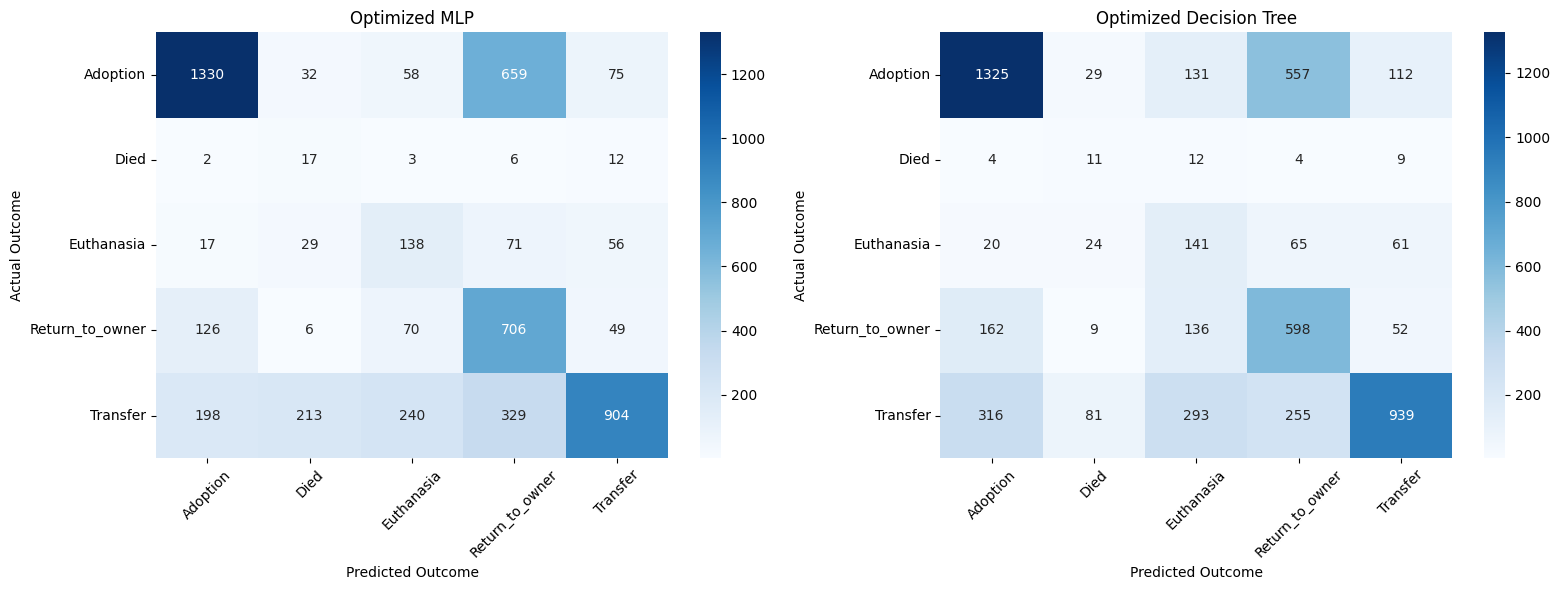

In [32]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Model predictions
predictions = {
    "Optimized MLP": y_dev_pred_mlp_optuna,
    "Optimized Decision Tree": y_dev_pred_best_tree
}

# Class labels in a consistent order
class_labels = [
    "Adoption",
    "Died",
    "Euthanasia",
    "Return_to_owner",
    "Transfer"
]

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(
        y_dev,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Outcome")
    ax.set_ylabel("Actual Outcome")

    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()


### Normalized confusion matrices

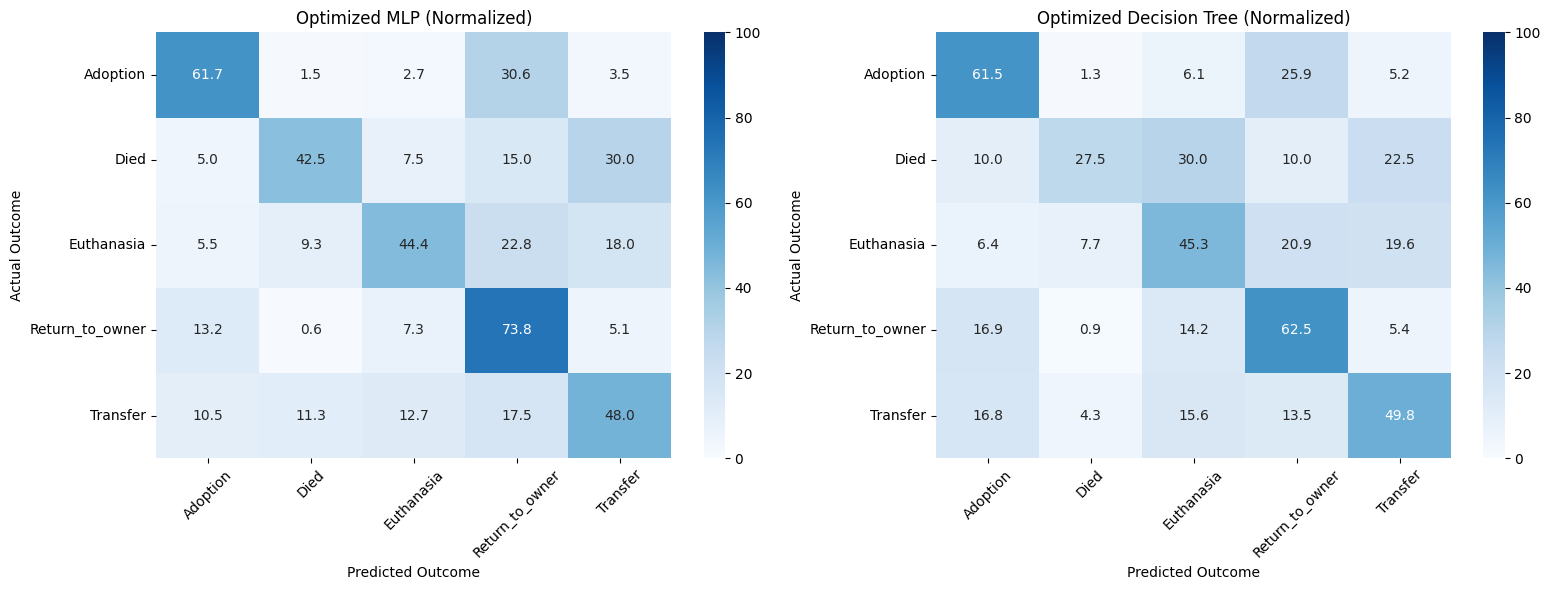

In [33]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):

    cm_normalized = confusion_matrix(
        y_dev,
        y_pred,
        labels=class_labels,
        normalize='true'
    ) * 100

    sns.heatmap(
        cm_normalized,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax,
        vmin=0,
        vmax=100
    )

    ax.set_title(f"{model_name} (Normalized)")
    ax.set_xlabel("Predicted Outcome")
    ax.set_ylabel("Actual Outcome")

    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()
